In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN

In [2]:
from sklearn.decomposition import PCA

In [3]:
df = pd.read_csv('blood.csv')

In [4]:
df.head

<bound method NDFrame.head of      V1  V2     V3  V4  Class
0     2  50  12500  98      2
1     0  13   3250  28      2
2     1  16   4000  35      2
3     2  20   5000  45      2
4     1  24   6000  77      1
..   ..  ..    ...  ..    ...
743  23   2    500  38      1
744  21   2    500  52      1
745  23   3    750  62      1
746  39   1    250  39      1
747  72   1    250  72      1

[748 rows x 5 columns]>

In [5]:
df.tail

<bound method NDFrame.tail of      V1  V2     V3  V4  Class
0     2  50  12500  98      2
1     0  13   3250  28      2
2     1  16   4000  35      2
3     2  20   5000  45      2
4     1  24   6000  77      1
..   ..  ..    ...  ..    ...
743  23   2    500  38      1
744  21   2    500  52      1
745  23   3    750  62      1
746  39   1    250  39      1
747  72   1    250  72      1

[748 rows x 5 columns]>

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 748 entries, 0 to 747
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   V1      748 non-null    int64
 1   V2      748 non-null    int64
 2   V3      748 non-null    int64
 3   V4      748 non-null    int64
 4   Class   748 non-null    int64
dtypes: int64(5)
memory usage: 29.3 KB


In [7]:
df.isnull().sum()

V1       0
V2       0
V3       0
V4       0
Class    0
dtype: int64

In [8]:
X = df[['V1', 'V2', 'V4']].copy()

In [9]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [13]:
db = DBSCAN(eps=0.5, min_samples=6)
df['Cluster'] = db.fit_predict(X_scaled)

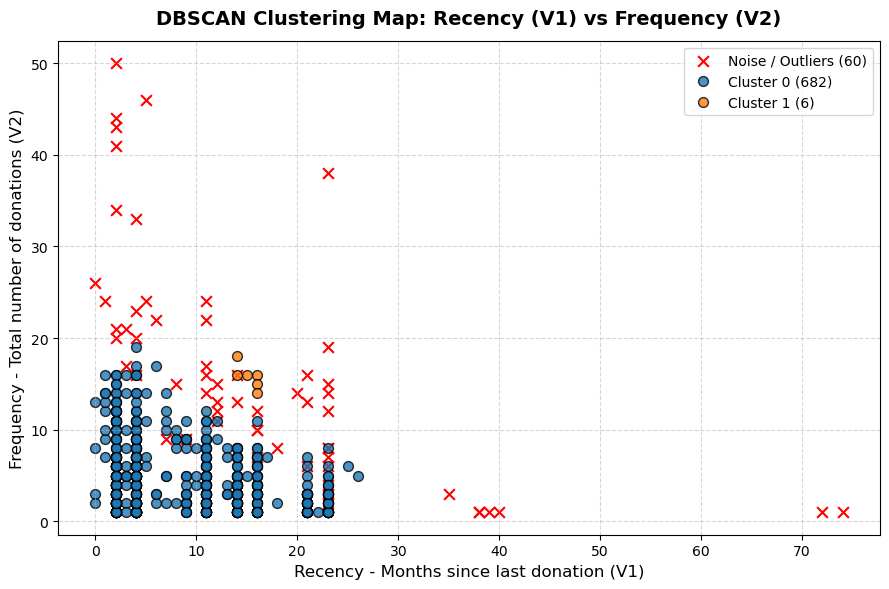

In [16]:
plt.figure(figsize=(9, 6))

unique_clusters = sorted(df['Cluster'].unique())
for cluster_id in unique_clusters:
    sub = df[df['Cluster'] == cluster_id]
    if cluster_id == -1:
        plt.scatter(
            sub['V1'], sub['V2'],
            c='red', marker='x', s=60, label=f'Noise / Outliers ({len(sub)})'
        )
    else:
        plt.scatter(
            sub['V1'], sub['V2'],
            edgecolors='k', alpha=0.8, s=50, label=f'Cluster {cluster_id} ({len(sub)})'
        )

plt.title('DBSCAN Clustering Map: Recency (V1) vs Frequency (V2)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Recency - Months since last donation (V1)', fontsize=12)
plt.ylabel('Frequency - Total number of donations (V2)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(frameon=True, loc='upper right')
plt.tight_layout()
plt.show()

In [ ]:
'''

# Plot panna ppora graph-oda size-ah set panrom (width: 9 inches, height: 6 inches)
plt.figure(figsize=(9, 6))

# DBSCAN kooduththa cluster labels-la unique values mattum eduthu sort panrom (eg: [-1, 0])
unique_clusters = sorted(df['Cluster'].unique())

# Ovvoru cluster-ah thani thaniya eduthu plot panrathukku loop podrom
for cluster_id in unique_clusters:
    # Ippo antha specific cluster-la irukra data rows mattum filter panni edukkurom
    sub = df[df['Cluster'] == cluster_id]
    
    # DBSCAN-la -1 na noise/outliers nu artham (entha cluster-layum seratha thani data points)
    if cluster_id == -1:
        # Outliers-ah red color-la 'x' mark vachu highlight panni kattron
        plt.scatter(
            sub['V1'], sub['V2'],
            c='red', marker='x', s=60, label=f'Noise / Outliers ({len(sub)})'
        )
    else:
        # Proper clusters-ah normal circle dots-ah black border pottu draw panrom
        plt.scatter(
            sub['V1'], sub['V2'],
            edgecolors='k', alpha=0.8, s=50, label=f'Cluster {cluster_id} ({len(sub)})'
        )

# Graph-ku title vaikkurom (Recency vs Frequency map)
plt.title('DBSCAN Clustering Map: Recency (V1) vs Frequency (V2)', fontsize=14, fontweight='bold', pad=12)

# X-axis label: Kadaisiya eppo raththam kuduthanga (Months since last donation)
plt.xlabel('Recency - Months since last donation (V1)', fontsize=12)

# Y-axis label: Moththam ethana thadava kuduthanga (Total number of donations)
plt.ylabel('Frequency - Total number of donations (V2)', fontsize=12)

# Background-la light-ah grid lines kaata solrom, read panna easy-ah irukum
plt.grid(True, linestyle='--', alpha=0.5)

# Enna color enna cluster nu therika right-top corner-la legend box podrom
plt.legend(frameon=True, loc='upper right')

# Margin gaps cut aagama graph neat-ah fit aaga tight_layout kodukrom
plt.tight_layout()

# Final-ah graph-ah screen-la display panrom
plt.show()


'''

